# 06 · Neural networks

Three networks per task, trained through the same walk-forward folds as every other model (`scripts/run_neural.py`, `src/fxml/models/neural.py`):

- **MLP:** each day's features (the same 50 inputs as the classical models) through two hidden layers of 64 and 32 units;
- **LSTM:** the last 20 trading days of those features through an LSTM with 32 units.
- **Transformer** (added as an extension): the same 20 days through two self-attention layers with 32 units and 4 heads, plus a learned position embedding.

Networks are refitted every quarter. At each refit the network is trained on the fitting rows with early stopping on the validation slice, then a fresh network is trained on the whole training window for the chosen number of epochs. Each network is trained with three seeds and the forecasts are averaged. Volatility forecasts are scaled on the validation slice like the classical models'.

The results sit in the same tables as the baselines and classical models (`reports/tables/ml_*.csv`); here they are compared with HAR-RV and with LightGBM, the best classical volatility model.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fxml import viz
from fxml.config import load_config
from fxml.validation.evaluate import aligned, loss
from fxml.validation.stats_tests import diebold_mariano

cfg = load_config()
viz.apply_style()
tables = cfg.paths.reports / "tables"
vol = pd.read_csv(tables / "ml_volatility.csv")
direction = pd.read_csv(tables / "ml_direction.csv")
ret = pd.read_csv(tables / "ml_returns.csv")
seeds = pd.read_csv(tables / "ml_neural_seeds.csv")
training = pd.read_csv(tables / "ml_neural_training.csv")
predictions = pd.read_parquet(cfg.paths.reports / "predictions" / "ml.parquet")
pairs = list(cfg.pairs)
pd.set_option("display.precision", 4)
NAMES = {"lightgbm": "LightGBM", "mlp": "MLP", "lstm": "LSTM", "transformer": "Transformer"}

## Volatility

In [2]:
show = ["baseline_har", "ridge", "lightgbm", "mlp", "lstm", "transformer"]
cols = ["qlike", "rmse_log", "mz_r2", "mz_slope", "pairs_significantly_better"]
vol[vol.pair == "average"].set_index("model").loc[show, cols]

,qlike,rmse_log,mz_r2,mz_slope,pairs_significantly_better
model,,,,,
baseline_har,0.1566,0.4968,0.5456,0.9346,0.0
ridge,0.1556,0.4880,0.5590,0.9784,3.0
lightgbm,0.1470,0.4763,0.5739,0.9923,5.0
mlp,0.1511,0.4911,0.5660,0.9793,3.0
lstm,0.1586,0.4973,0.5518,0.9951,0.0
transformer,0.1607,0.5051,0.5415,0.9713,0.0


PosixPath('./reports/figures/nn_volatility_vs_har.png')

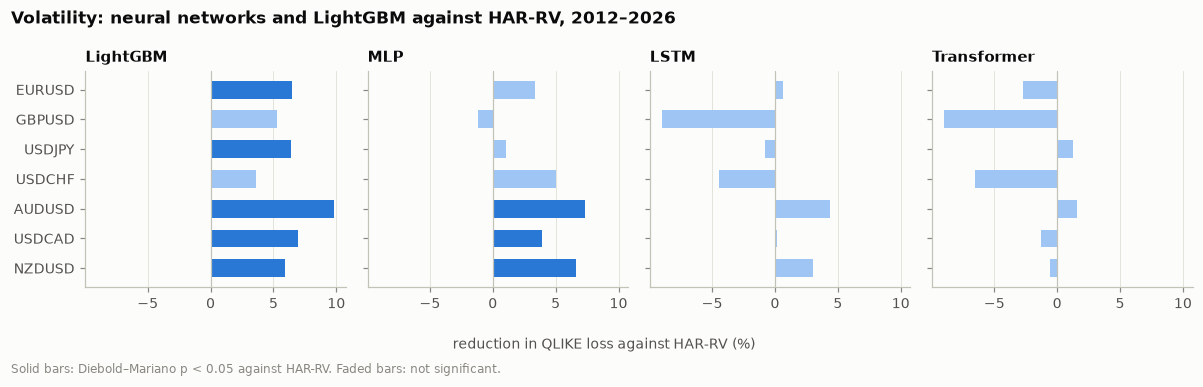

In [3]:
qlike = vol[vol.pair != "average"].pivot(index="pair", columns="model", values="qlike").loc[pairs]
gain = 100 * (1 - qlike.div(qlike["baseline_har"], axis=0))
significant = vol[vol.pair != "average"].assign(
    better=lambda d: (d.dm_vs_baseline_har < 0) & (d.dm_p_vs_baseline_har < 0.05)
).pivot(index="pair", columns="model", values="better").loc[pairs]

fig, axes = plt.subplots(1, 4, figsize=(11, 3.2), sharex=True, sharey=True)
for ax, model in zip(axes, NAMES):
    colors = [viz.CATEGORICAL[0] if s else viz.SEQUENTIAL_BLUE[1] for s in significant[model]]
    ax.barh(pairs, gain[model], color=colors, height=0.6)
    ax.axvline(0, color=viz.BASELINE, lw=0.8)
    ax.set_title(NAMES[model])
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.supxlabel("reduction in QLIKE loss against HAR-RV (%)", color=viz.INK_SECONDARY, fontsize=9)
fig.suptitle("Volatility: neural networks and LightGBM against HAR-RV, 2012–2026", x=0.01,
             ha="left", fontweight="bold")
fig.text(0.01, -0.05, "Solid bars: Diebold–Mariano p < 0.05 against HAR-RV. Faded bars: not significant.",
         color=viz.INK_MUTED, fontsize=8)
fig.tight_layout()
viz.save(fig, "nn_volatility_vs_har")

In [4]:
# Do the networks beat LightGBM? Diebold-Mariano on daily QLIKE; negative favours the network.
rows = []
for task, reference in [("volatility", "lightgbm"), ("direction", "logistic_l2"), ("returns", "ridge")]:
    for pair in pairs:
        group = predictions[(predictions.task == task) & (predictions.pair == pair)]
        wide, actual = aligned(group)
        for model in ["mlp", "lstm", "transformer"]:
            stat, p = diebold_mariano(loss(task, actual, wide[model]), loss(task, actual, wide[reference]))
            rows.append({"task": task, "against": reference, "model": model, "pair": pair, "dm": stat, "p": p})
versus = pd.DataFrame(rows)
summary = versus.assign(better=lambda d: (d.dm < 0) & (d.p < 0.05), worse=lambda d: (d.dm > 0) & (d.p < 0.05))
summary.groupby(["task", "against", "model"])[["better", "worse"]].sum().rename(
    columns={"better": "pairs_significantly_better", "worse": "pairs_significantly_worse"})

pairs_significantly_better  \
task       against     model                                     
direction  logistic_l2 lstm                                  0   
                       mlp                                   0   
                       transformer                           0   
returns    ridge       lstm                                  0   
                       mlp                                   0   
                       transformer                           0   
volatility lightgbm    lstm                                  0   
                       mlp                                   0   
                       transformer                           0   

                                    pairs_significantly_worse  
task       against     model                                   
direction  logistic_l2 lstm                                 0  
                       mlp                                  0  
                       transformer                          6  
returns    ridge       lstm                                 2  
                       mlp                                  1  
                       transformer                          7  
volatility lightgbm    lstm                                 5  
                       mlp                                  2  
                       transformer                          7

## Direction and returns

In [5]:
show = ["baseline_frequency", "logistic_l2", "lightgbm", "mlp", "lstm", "transformer"]
cols = ["accuracy", "roc_auc", "brier", "share_called_up", "pairs_significantly_better"]
direction[direction.pair == "average"].set_index("model").loc[show, cols]

,accuracy,roc_auc,brier,share_called_up,pairs_significantly_better
model,,,,,
baseline_frequency,0.4990,0.4901,0.2502,0.6779,1.0
logistic_l2,0.5029,0.5030,0.2507,0.6180,0.0
lightgbm,0.5023,0.5044,0.2530,0.5364,0.0
mlp,0.5036,0.5034,0.2504,0.5103,1.0
lstm,0.4997,0.4979,0.2506,0.5046,0.0
transformer,0.5015,0.5012,0.2522,0.5620,1.0


In [6]:
show = ["baseline_zero", "ridge", "lightgbm", "mlp", "lstm", "transformer"]
ret[ret.pair == "average"].set_index("model").loc[show, ["rmse", "r2_oos", "sign_hit_rate", "pairs_significantly_better"]]

,rmse,r2_oos,sign_hit_rate,pairs_significantly_better
model,,,,
baseline_zero,0.0055,0.0000,NaN,0.0
ridge,0.0056,-0.0025,0.4961,0.0
lightgbm,0.0056,-0.0210,0.4950,0.0
mlp,0.0056,-0.0040,0.4985,0.0
lstm,0.0056,-0.0063,0.4980,0.0
transformer,0.0056,-0.0166,0.4976,0.0


## Seeds

Each seed's headline metric averaged over pairs (QLIKE for volatility, ROC AUC for direction, out-of-sample R² for returns), next to the average of the three seeds' forecasts.

In [7]:
seeds.pivot_table(index=["task", "model", "metric"], columns="seed", values="value")

seed                                 0       1       2  average
task       model       metric                                  
direction  lstm        roc_auc  0.5015  0.4989  0.4941   0.4979
           mlp         roc_auc  0.5040  0.5043  0.4996   0.5034
           transformer roc_auc  0.4987  0.5025  0.5018   0.5012
returns    lstm        r2_oos  -0.0116 -0.0105 -0.0123  -0.0063
           mlp         r2_oos  -0.0098 -0.0077 -0.0071  -0.0040
           transformer r2_oos  -0.0225 -0.0235 -0.0320  -0.0166
volatility lstm        qlike    0.1650  0.1603  0.1597   0.1586
           mlp         qlike    0.1545  0.1519  0.1534   0.1511
           transformer qlike    0.1678  0.1638  0.1645   0.1607

## How long the networks train

The number of epochs early stopping chose at each quarterly refit, over pairs and seeds. A network that stops after one or two epochs found nothing in the training data that also holds on the validation slice.

In [8]:
training.groupby(["task", "model"])["epochs"].describe()[["mean", "25%", "50%", "75%", "max"]]

mean   25%   50%   75%   max
task       model                                       
direction  lstm          3.6183   1.0   2.0   4.0  25.0
           mlp           3.4611   1.0   2.0   4.0  48.0
           transformer   3.8238   2.0   3.0   5.0  24.0
returns    lstm          4.1214   2.0   3.0   5.0  25.0
           mlp           3.7151   2.0   3.0   5.0  29.0
           transformer   5.9722   4.0   5.0   8.0  42.0
volatility lstm         19.3032  12.0  17.0  25.0  66.0
           mlp          18.4929   7.0  14.0  26.0  92.0
           transformer  14.1643   9.0  13.0  19.0  51.0

PosixPath('./reports/figures/nn_epochs.png')

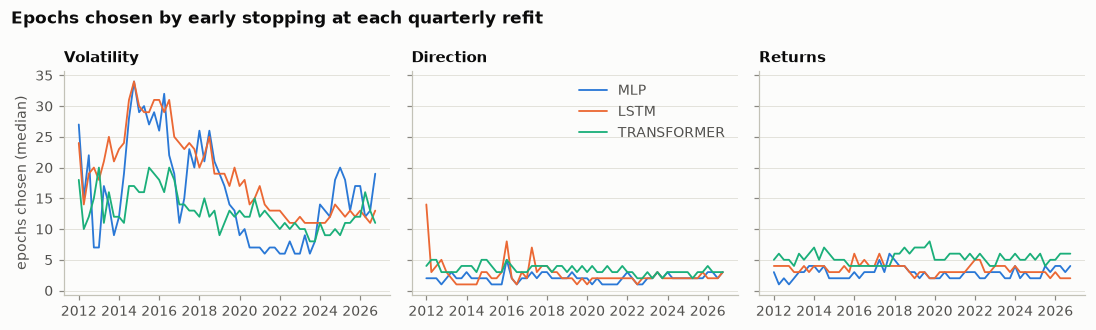

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, task in zip(axes, ["volatility", "direction", "returns"]):
    for i, model in enumerate(["mlp", "lstm", "transformer"]):
        rows = training[(training.task == task) & (training.model == model)]
        median = rows.groupby("period")["epochs"].median()
        ax.plot(pd.to_datetime(median.index), median.to_numpy(),
                color=viz.CATEGORICAL[i], label=model.upper(), lw=1.2)
    ax.set_title(task.capitalize())
axes[0].set_ylabel("epochs chosen (median)")
axes[1].legend(loc="upper right")
fig.suptitle("Epochs chosen by early stopping at each quarterly refit", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
viz.save(fig, "nn_epochs")

## Findings

**The MLP beats HAR-RV but not LightGBM.** Its average QLIKE loss is 0.151, 3.5% below HAR-RV's 0.157, and it is significantly better on 3 of 7 pairs (AUD/USD, USD/CAD and NZD/USD). LightGBM stays ahead at 0.147: the MLP is significantly worse than LightGBM on 2 pairs and better on none. Like LightGBM, the MLP forecasts are almost unbiased (Mincer–Zarnowitz slope 0.98).

**The LSTM adds nothing.** With 20 days of history it is 1.3% worse than HAR-RV on average, better on no pair, and significantly worse than LightGBM on 5 pairs. The features already summarise the past well (realized variance over 1, 5 and 22 days, the GARCH forecast, momentum and moving averages), so the sequence model has little left to discover. It also has only 1,500 to 5,000 training windows per pair to learn its recurrent weights from.

**The Transformer adds nothing either.** Added as an extension, it scores a volatility QLIKE of 0.161, 2.6% worse than HAR-RV and behind both the LSTM and the MLP, and beats HAR-RV on no pair. It is also the slowest model by far (about 35 minutes per volatility job). Notebook 08 discusses it with the other extensions.

**Direction and returns stay unpredictable.** Both networks sit at chance on direction (accuracy 50.0% and 50.4%, AUC 0.50). The MLP passes the Pesaran–Timmermann test on one pair, which is about what chance alone gives across seven pairs. Neither network beats the zero forecast for returns (out-of-sample R² of −0.4% and −0.6%).

**Early stopping confirms it.** On direction and returns, early stopping halts after a median of 2 to 3 epochs: whatever a network learns from the training rows does not hold on the validation slice. Volatility networks train for a median of 14 to 17 epochs, fewer in later years as each epoch covers more data.

**Averaging seeds helps.** For every task and network the average of the three seeds' forecasts beats each single seed. The volatility MLP's single seeds score 0.152 to 0.155 against 0.151 for their average, and the LSTM's 0.160 to 0.165 against 0.159. Reporting one seed would have understated the networks and made them look less stable.

**For Phase 6.** LightGBM remains the volatility forecast to carry into the backtest and Value at Risk, with the MLP as a second opinion. No model, classical or neural, gives a direction signal that beats chance.